In [37]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Étape 4 — Optimisation et évaluation.


1 - Imports et chargement des données


In [ ]:
df = pd.read_csv("../data/raw/student_mental_health.csv")

X = df.drop(columns=["Student_ID", "Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

data = joblib.load("../data/processed/preprocessed_data.joblib")

preprocessor = data["preprocessor"]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (1600, 15)
Testing: (400, 15)


2 - Reproducing the data cleaning


In [ ]:
# invalid_train = (
#     X_train["Social_Media_Hours"] > X_train["Screen_Time_Hours"]
# )

# invalid_test = (
#     X_test["Social_Media_Hours"] > X_test["Screen_Time_Hours"]
# )

# print("Training inconsistencies:", invalid_train.sum())
# print("Testing inconsistencies:", invalid_test.sum())

# X_train.loc[invalid_train, "Social_Media_Hours"] = X_train.loc[invalid_train, "Screen_Time_Hours"]
# X_test.loc[invalid_test, "Social_Media_Hours"] = X_test.loc[invalid_test, "Screen_Time_Hours"]

3 - Création d'un pipeline pour chaque modèle


In [4]:
pipelines = {
    "Logistic Regression": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                ),
            ),
        ]
    ),
    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                RandomForestClassifier(
                    random_state=42,
                ),
            ),
        ]
    ),
    "KNN": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", KNeighborsClassifier()),
        ]
    ),
}

4 - Définition des hyperparamètres pour chaque modèle


In [5]:
param_grids = {
    "Logistic Regression": {"classifier__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_split": [2, 5],
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9],
        "classifier__weights": ["uniform", "distance"],
    },
}

5 - Création de GridSearchCV


In [ ]:
grid_searches = {}

for name, pipeline in pipelines.items():
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1,
        verbose=1,
    )

    grid_searches[name] = grid_search

# grid_searches


6 - Train the Models with GridSearchCV


In [ ]:
for name, grid_search in grid_searches.items():
    print(f"\nOptimizing: {name}")

    grid_search.fit(X_train, y_train)

    print("Best parameters:", grid_search.best_params_)
    print("Best cross validation F1:", grid_search.best_score_)


Optimizing: Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'classifier__C': 1}
Best cross validation F1: 0.7478660996718108

Optimizing: Random Forest
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}
Best cross validation F1: 0.6836286978537176

Optimizing: KNN
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'classifier__n_neighbors': 7, 'classifier__weights': 'distance'}
Best cross validation F1: 0.6428899283505649


7 - Compare the Optimized Models


In [ ]:
results = []

for name, grid_search in grid_searches.items():
    results.append(
        {
            "Model": name,
            "Best CV F1": grid_search.best_score_,
            "Best Parameters": grid_search.best_params_,
        }
    )

optimization_results = pd.DataFrame(results)

optimization_results = optimization_results.sort_values(
    by="Best CV F1", ascending=False
)

optimization_results

,Model,Best CV F1,Best Parameters
0,Logistic Regression,0.747866,{'classifier__C': 1}
1,Random Forest,0.683629,"{'classifier__max_depth': 20, 'classifier__min..."
2,KNN,0.642890,"{'classifier__n_neighbors': 7, 'classifier__we..."


8 - Select the Best Model


In [ ]:
best_model_name = max(
    grid_searches,
    key=lambda name: grid_searches[name].best_score_,
)

# print(best_model_name)
best_model = grid_searches[best_model_name].best_estimator_

print("model name:", best_model_name)
print("best parameters: ", grid_searches[best_model_name].best_params_)
print("Best cv f1: ", grid_searches[best_model_name].best_score_)


model name: Logistic Regression
best parameters:  {'classifier__C': 1}
Best cv f1:  0.7478660996718108


9 - Final Evaluation on Test Set


In [28]:
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")


print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.7625
Precision: 0.761694715630901
Recall: 0.7625
F1-score: 0.762047851222878


10 - Classification Report


In [31]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
    )
)

              precision    recall  f1-score   support

         Low       0.82      0.82      0.82       132
      Medium       0.65      0.64      0.64       132
        High       0.81      0.83      0.82       136

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400



11 - Confusion Matrix

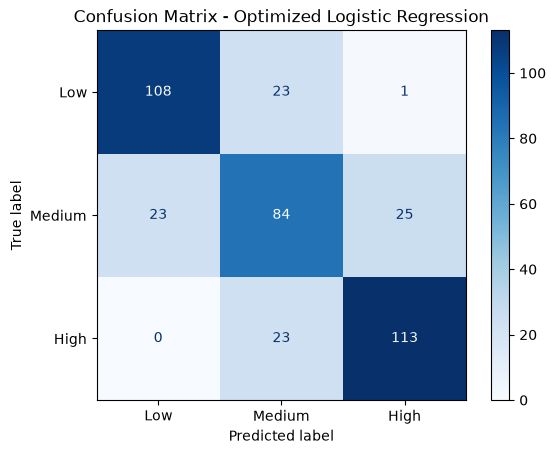

In [34]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"],
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"],
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Optimized Logistic Regression")
plt.show()

12 - Save the Complete Pipeline

In [38]:
Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, "../models/best_model_pipeline.joblib")

['../models/best_model_pipeline.joblib']